# Experimento 11 — H2O AutoML vs. TabPFN

Mesmas 14 features do Exp. 8, categorias separadas e margens brutas. Descoberta H2O
com histórico anterior a 2023; candidatos fixos avaliados em 2023, 2024 e 2025.
Ranking por RMSE ponderado e Logistic Brier ponderada, com os mesmos pesos do Exp. 10.

Leia [instalação e execução](../../docs/exp11.md). TabPFN exige GPU por padrão.
O notebook não contém resultados simulados. Executar as células de treinamento inicia
o experimento completo; o piloto também exige os pesos do TabPFN e CUDA.

In [10]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

pasta_atual = Path.cwd().resolve()
raiz = next(p for p in [pasta_atual, *pasta_atual.parents] if (p / 'raw_data').is_dir())
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))
from src.data_processing import carregar_dados, preparar_seeds, organizar_jogos
from src.features import (
    adicionar_seeds, calcular_estatisticas_agregadas, adicionar_estatisticas,
    ESTATISTICAS_DETALHADAS, calcular_estatisticas_detalhadas, adicionar_estatisticas_detalhadas,
)
from src.submission import preparar_confrontos
from src.automl_h2o import inicializar_h2o
from src.season_similarity import construir_perfis_temporadas, ranquear_temporadas, ponderar_temporadas
from src.exp11 import (
    versoes, detectar_tabpfn, candidatos_tabpfn, descobrir_h2o, avaliar_corte,
    avaliar_banco, rankings, gerar_submissions, salvar_json, validar_historico,
)

FEATURES = ['SeedDif', 'WinRateDiff', 'AvgPointsForDiff', 'AvgPointsAgainstDiff', 'OppWinRateDiff',
            *[nome + 'Diff' for nome in ESTATISTICAS_DETALHADAS]]
assert len(FEATURES) == 14
INICIO_DETALHADO = {'M': 2003, 'W': 2010}
CATEGORIAS = {'M': 'Masculino', 'W': 'Feminino'}
ANOS_VALIDACAO = [2023, 2024, 2025]
TEMPORADA_PREVISAO = 2026
LIMITE_DAYNUM_PREVISAO = 134
SEED = 42
MAX_MODELS_H2O = 100
TOP_BASE_H2O = 20
N_FOLDS = 5
EXIGIR_GPU = True
N_THREADS = 2
MAX_MEM_SIZE = '4G'
# None usa max(1h, tempo H2O da categoria); limite verificado entre candidatos.
ORCAMENTO_TABPFN_SEGUNDOS_POR_CATEGORIA = None
REPETIR_FALHAS = False
CHECKPOINTS = raiz / 'checkpoints' / 'exp11'
display(versoes())

{'h2o': '3.46.0.12',
 'tabpfn': '9.2.0',
 'torch': '2.11.0+cu128',
 'numpy': '2.2.6',
 'pandas': '2.3.2',
 'scikit-learn': '1.7.1',
 'psutil': '7.2.2'}

## Ambiente

Esta célula não ajusta modelos. CUDA ausente provoca erro explícito. Os modelos
H2O disponíveis neste Windows usam CPU; XGBoost é incluído apenas se o backend
estiver disponível (em ambiente compatível, `backend=auto` pode usar GPU).

In [11]:
ambiente_tabpfn = detectar_tabpfn(exigir_gpu=EXIGIR_GPU)
ambiente_h2o = inicializar_h2o(max_mem_size=MAX_MEM_SIZE, nthreads=N_THREADS)
display(ambiente_tabpfn, ambiente_h2o)
salvar_json(CHECKPOINTS / 'ambiente.json', {'tabpfn': ambiente_tabpfn, 'h2o': ambiente_h2o})

Cannot build an XGBoost model - no backend found.


{'device': 'cuda:0',
 'cuda': '12.8',
 'gpu': 'NVIDIA GeForce RTX 3060',
 'vram_gb': 11.99951171875,
 'versoes': {'h2o': '3.46.0.12',
  'tabpfn': '9.2.0',
  'torch': '2.11.0+cu128',
  'numpy': '2.2.6',
  'pandas': '2.3.2',
  'scikit-learn': '1.7.1',
  'psutil': '7.2.2'}}

{'h2o_version': '3.46.0.12',
 'cluster_version': '3.46.0.12',
 'xgboost_disponivel': False,
 'exclude_algos': ['DeepLearning', 'XGBoost'],
 'limitacao': 'XGBoost indisponível neste backend H2O; demais famílias habilitadas.'}

## Dados pré-NCAA

M desde 2003, W desde 2010. Mantemos as verificações do Exp. 10: DayNum anterior
ao torneio, ausência de jogos NCAA nas features, Target = ScoreA − ScoreB e diferenças A − B.

In [12]:
dados = {
    categoria: carregar_dados(raiz / "raw_data", categoria, incluir_regular=True, incluir_detalhado=True)
    for categoria in CATEGORIAS
}
assert set(dados["M"]["times"]["TeamID"]).isdisjoint(set(dados["W"]["times"]["TeamID"]))
seeds, estatisticas, detalhadas, jogos, limites, coberturas = {}, {}, {}, {}, {}, []
chaves_jogo = ["Season", "DayNum", "WTeamID", "LTeamID"]
for categoria, base in dados.items():
    torneios = base["resultados"].loc[base["resultados"]["Season"] < TEMPORADA_PREVISAO].copy()
    limites[categoria] = torneios.groupby("Season")["DayNum"].min().to_dict()
    limites[categoria][TEMPORADA_PREVISAO] = LIMITE_DAYNUM_PREVISAO
    raw_detalhes = base["temporada_regular_detalhada"]
    assert raw_detalhes["Season"].min() == INICIO_DETALHADO[categoria]
    anos = set(raw_detalhes["Season"]) & set(limites[categoria])
    assert set([*ANOS_VALIDACAO, TEMPORADA_PREVISAO]).issubset(anos)
    regulares = base["temporada_regular"].loc[base["temporada_regular"]["Season"].isin(anos)].copy()
    detalhes = raw_detalhes.loc[raw_detalhes["Season"].isin(anos)].copy()
    ids = set(base["times"]["TeamID"])
    for tabela in [regulares, detalhes]:
        assert (tabela["DayNum"] < tabela["Season"].map(limites[categoria])).all()
        assert tabela.merge(torneios[chaves_jogo], on=chaves_jogo).empty
        assert tabela["WTeamID"].isin(ids).all() and tabela["LTeamID"].isin(ids).all()
    conferidos = detalhes.merge(regulares[chaves_jogo + ["WScore", "LScore"]],
        on=chaves_jogo, how="left", suffixes=("", "Compact"), validate="one_to_one", indicator=True)
    assert conferidos["_merge"].eq("both").all()
    for placar in ["WScore", "LScore"]:
        np.testing.assert_array_equal(conferidos[placar], conferidos[placar + "Compact"])

    cobertura = regulares.groupby("Season").size().rename("JogosCompact").to_frame()
    cobertura["JogosDetalhados"] = detalhes.groupby("Season").size()
    cobertura["SemDetalhes"] = cobertura["JogosCompact"] - cobertura["JogosDetalhados"]
    cobertura["Cobertura"] = cobertura["JogosDetalhados"] / cobertura["JogosCompact"]
    cobertura["UltimoDayNumDetalhado"] = detalhes.groupby("Season")["DayNum"].max()
    cobertura["LimiteExclusivo"] = cobertura.index.map(limites[categoria])
    coberturas.append(cobertura.reset_index().assign(Categoria=categoria))
    seeds[categoria] = preparar_seeds(base["seeds"])
    estatisticas[categoria] = calcular_estatisticas_agregadas(regulares, limites_daynum=limites[categoria])
    detalhadas[categoria] = calcular_estatisticas_detalhadas(detalhes, limites_daynum=limites[categoria])
    historico = torneios.loc[torneios["Season"].isin(anos)]
    tabela = adicionar_seeds(organizar_jogos(historico), seeds[categoria])
    tabela = adicionar_estatisticas(tabela, estatisticas[categoria])
    tabela = adicionar_estatisticas_detalhadas(tabela, detalhadas[categoria])
    assert len(tabela) == len(historico)
    assert (tabela["TeamA"] < tabela["TeamB"]).all()
    assert tabela["Target"].equals(tabela["ScoreA"] - tabela["ScoreB"])
    assert tabela["SeedDif"].equals(tabela["SeedA"] - tabela["SeedB"])
    assert np.isfinite(tabela[FEATURES].to_numpy()).all()
    for stats, nomes in [(estatisticas[categoria], ["WinRate", "AvgPointsFor", "AvgPointsAgainst", "OppWinRate"]),
                          (detalhadas[categoria], ESTATISTICAS_DETALHADAS)]:
        lookup = stats.set_index(["Season", "TeamID"])
        for nome in nomes:
            a = lookup[nome].reindex(pd.MultiIndex.from_frame(tabela[["Season", "TeamA"]])).to_numpy()
            b = lookup[nome].reindex(pd.MultiIndex.from_frame(tabela[["Season", "TeamB"]])).to_numpy()
            np.testing.assert_allclose(tabela[nome + "Diff"], a - b)
    jogos[categoria] = tabela

cobertura = pd.concat(coberturas, ignore_index=True)
display(cobertura)

divisoes = pd.DataFrame([
    {"Categoria": categoria, "AnoValidacao": ano,
     "PrimeiroAnoTreino": tabela.loc[tabela.Season < ano, "Season"].min(),
     "UltimoAnoTreino": tabela.loc[tabela.Season < ano, "Season"].max(),
     "JogosTreino": int(tabela.Season.lt(ano).sum()), "JogosValidacao": int(tabela.Season.eq(ano).sum())}
    for categoria, tabela in jogos.items() for ano in ANOS_VALIDACAO
])
assert (divisoes.UltimoAnoTreino < divisoes.AnoValidacao).all()
assert divisoes.JogosValidacao.gt(0).all()
assert divisoes.loc[divisoes.AnoValidacao.eq(2021), "UltimoAnoTreino"].eq(2019).all()
for categoria, tabela in jogos.items():
    assert tabela.Season.max() == 2025
    assert tabela.Season.min() == INICIO_DETALHADO[categoria]
    assert np.isfinite(tabela[[*FEATURES, "Target"]].to_numpy()).all()
display(divisoes)

,Season,JogosCompact,JogosDetalhados,SemDetalhes,Cobertura,UltimoDayNumDetalhado,LimiteExclusivo,Categoria
0,2003,4616,4616,0,1.000000,132,134,M
1,2004,4571,4571,0,1.000000,132,134,M
2,2005,4675,4675,0,1.000000,132,134,M
3,2006,4757,4757,0,1.000000,132,134,M
4,2007,5043,5043,0,1.000000,132,134,M
5,2008,5163,5163,0,1.000000,132,134,M
6,2009,5249,5249,0,1.000000,132,134,M
7,2010,5263,5263,0,1.000000,132,134,M
8,2011,5246,5246,0,1.000000,132,134,M
9,2012,5253,5253,0,1.000000,132,134,M


,Categoria,AnoValidacao,PrimeiroAnoTreino,UltimoAnoTreino,JogosTreino,JogosValidacao
0,M,2023,2003,2022,1248,67
1,M,2024,2003,2023,1315,67
2,M,2025,2003,2024,1382,67
3,W,2023,2010,2022,760,67
4,W,2024,2010,2023,827,67
5,W,2025,2010,2024,894,67


In [13]:
validar_historico(jogos, FEATURES)
display(pd.concat(jogos, names=['Categoria']).groupby(level='Categoria')[FEATURES].agg(['min', 'max']))

SeedDif     WinRateDiff           AvgPointsForDiff             \
              min max         min       max              min        max   
Categoria                                                                 
M             -15  15   -0.633333  0.491657       -22.892857  21.643382   
W             -15  15   -0.468750  0.548387       -30.848485  29.424242   

          AvgPointsAgainstDiff            OppWinRateDiff            ...  \
                           min        max            min       max  ...   
Categoria                                                           ...   
M                   -25.035714  20.049242      -0.231545  0.221619  ...   
W                   -29.961481  27.809476      -0.273426  0.285006  ...   

          OffensiveReboundsPerGameDiff           DefensiveReboundsPerGameDiff  \
                                   min       max                          min   
Categoria                                                                       
M                            -9.214286  7.924632                    -9.285714   
W                            -9.026667  9.284761                    -9.849432   

                     TurnoversPerGameDiff           StealsPerGameDiff  \
                 max                  min       max               min   
Categoria                                                               
M           9.010776            -7.666667  7.580645         -6.205882   
W          11.595833            -8.475045  7.810484         -7.251812   

                    BlocksPerGameDiff            
                max               min       max  
Categoria                                        
M          6.283681         -6.752688  6.360606  
W          8.598925         -6.548387  6.909091  

[2 rows x 28 columns]

## Similaridade e pesos

Padronização ajustada apenas nos perfis anteriores a 2026. Os três anos de
avaliação são fixos: 2023–2025. A distância usa estatísticas pré-torneio, sem Target.
`RMSE_pond = Σ Peso_ano × RMSE_ano`; `LB_pond = Σ Peso_ano × LB_ano`.

In [14]:
perfis_resultado = construir_perfis_temporadas(dados, limites, inicio=INICIO_DETALHADO, ano_maximo=2026)
similaridade = ranquear_temporadas(perfis_resultado['perfis'], 2026, ANOS_VALIDACAO)
REFERENCIAS = ponderar_temporadas(similaridade['ranking'], n_referencias=3)
assert set(REFERENCIAS.Season) == set(ANOS_VALIDACAO)
assert max(similaridade['anos_padronizacao']) < 2026
np.testing.assert_allclose(REFERENCIAS.Peso.sum(), 1)
display(REFERENCIAS, similaridade['normalizacao'])
salvar_json(CHECKPOINTS / 'similaridade.json', {
    'referencias': REFERENCIAS.to_dict('records'), 'anos_padronizacao': similaridade['anos_padronizacao'],
    'normalizacao': similaridade['normalizacao'].to_dict('records')})

,Season,Distancia,Peso
0,2025,7.624698,0.374675
1,2024,8.193139,0.348680
2,2023,10.326554,0.276645


,Dimensao,MediaHistorica,DesvioHistorico,EscalaUsada
0,M_WinRate_mean,0.723001,0.010319,0.010319
1,M_WinRate_std,0.098814,0.006025,0.006025
2,M_AvgPointsFor_mean,74.591195,2.062284,2.062284
3,M_AvgPointsFor_std,4.702178,0.397449,0.397449
4,M_AvgPointsAgainst_mean,66.830807,2.106159,2.106159
5,M_AvgPointsAgainst_std,4.400017,0.450100,0.450100
6,M_OppWinRate_mean,0.529918,0.005319,0.005319
7,M_OppWinRate_std,0.054440,0.002686,0.002686
8,M_FGPercentage_mean,0.458217,0.004199,0.004199
9,M_FGPercentage_std,0.021864,0.001513,0.001513


## Descoberta H2O — uma busca por categoria

Até 100 modelos-base, cinco folds internos agrupados por temporada e RMSE interno.
Extraímos os 20 primeiros modelos-base; ensembles não são reconstruídos. Falhas
de extração e configurações duplicadas são registradas, sem substituir candidatos.
Fixamos alpha/lambda vencedores e o número de árvores efetivamente construído.
Os reajustes externos não fazem nova busca nem CV interna; recebem somente o treino.

In [15]:
import warnings
from h2o.exceptions import H2ODependencyWarning
warnings.filterwarnings('ignore', category=H2ODependencyWarning,
    message=r'Converting H2O frame to pandas dataframe using single-thread\.',
    module=r'h2o\.frame')
import importlib
import src.exp11 as modulo_exp11
importlib.reload(modulo_exp11)
modulo_exp11.configurar_avisos_h2o()
descobrir_h2o = modulo_exp11.descobrir_h2o
modulo_exp11.recuperar_descoberta_interrompida()

descobertas = {}
for cat in CATEGORIAS:
    descobertas[cat] = descobrir_h2o(jogos[cat], cat, features=FEATURES,
        pasta=CHECKPOINTS / 'descoberta', max_models=MAX_MODELS_H2O, top_n=TOP_BASE_H2O,
        seed=SEED, n_folds=N_FOLDS, exclude_algos=ambiente_h2o['exclude_algos'])
    display(pd.DataFrame(descobertas[cat]['leaderboard']))
    display(pd.DataFrame(descobertas[cat]['falhas']))
    print(cat, 'ensembles excluídos:', len(descobertas[cat]['ensembles_excluidos']))
candidatos_h2o = [c for d in descobertas.values() for c in d['candidatos']]
display(pd.DataFrame(candidatos_h2o))
assert all(sum(c['Categoria'] == cat for c in candidatos_h2o) >= 3 for cat in CATEGORIAS), 'Menos de três candidatos H2O: veja as falhas.'

,model_id,rmse,mse,mae,rmsle,mean_residual_deviance
0,GLM_1_AutoML_3_20261029_182441,11.311999,127.961318,8.914968,None,127.961318
1,StackedEnsemble_BestOfFamily_1_AutoML_3_202610...,11.367670,129.223914,8.946030,None,129.223914
2,StackedEnsemble_AllModels_1_AutoML_3_20261029_...,11.406616,130.110894,8.948387,None,130.110894
3,GBM_grid_1_AutoML_3_20261029_182441_model_42,11.534527,133.045303,9.120851,None,133.045303
4,GBM_grid_1_AutoML_3_20261029_182441_model_89,11.536202,133.083962,9.081615,None,133.083962
...,...,...,...,...,...,...
105,GBM_grid_1_AutoML_3_20261029_182441_model_98,12.218301,149.286873,9.584811,None,149.286873
106,GBM_grid_1_AutoML_3_20261029_182441_model_3,12.220987,149.352514,9.730083,None,149.352514
107,GBM_grid_1_AutoML_3_20261029_182441_model_30,12.257052,150.235314,9.648966,None,150.235314
108,GBM_grid_1_AutoML_3_20261029_182441_model_94,12.406166,153.912961,9.771466,None,153.912961


""


M ensembles excluídos: 2


,model_id,rmse,mse,mae,rmsle,mean_residual_deviance
0,GLM_1_AutoML_4_20261029_182528,12.289662,151.035795,9.815337,None,151.035795
1,StackedEnsemble_BestOfFamily_1_AutoML_4_202610...,12.314460,151.645930,9.852266,None,151.645930
2,StackedEnsemble_AllModels_1_AutoML_4_20261029_...,12.345808,152.418983,9.889574,None,152.418983
3,GBM_grid_1_AutoML_4_20261029_182528_model_59,12.632391,159.577307,10.100154,None,159.577307
4,GBM_grid_1_AutoML_4_20261029_182528_model_49,12.724886,161.922723,10.185559,None,161.922723
...,...,...,...,...,...,...
105,GBM_grid_1_AutoML_4_20261029_182528_model_110,13.791628,190.209009,10.935635,None,190.209009
106,GBM_grid_1_AutoML_4_20261029_182528_model_30,13.799982,190.439514,11.113025,None,190.439514
107,GBM_grid_1_AutoML_4_20261029_182528_model_91,13.850618,191.839630,10.960392,None,191.839630
108,GBM_grid_1_AutoML_4_20261029_182528_model_54,13.981551,195.483764,11.167109,None,195.483764


""


W ensembles excluídos: 2


,Candidato,Categoria,Abordagem,Familia,Parametros,ParametrosOriginais,ParametrosNulosOmitidos,AjustesReconstrucao,ModeloOrigem,PosicaoLeaderboard,RMSEInterno
0,M_h2o_afec215223f32962,M,h2o,glm,"{'seed': 42, 'ignore_const_cols': True, 'score...","{'model_id': 'GLM_1_AutoML_3_20261029_182441',...",[],"{'stopping_rounds': 0, 'max_runtime_secs': 0, ...",GLM_1_AutoML_3_20261029_182441,1,11.311999
1,M_h2o_6c07c5bc4a871ead,M,h2o,gbm,"{'score_each_iteration': False, 'score_tree_in...",{'model_id': 'GBM_grid_1_AutoML_3_20261029_182...,[],"{'stopping_rounds': 0, 'max_runtime_secs': 0, ...",GBM_grid_1_AutoML_3_20261029_182441_model_42,4,11.534527
2,M_h2o_3a62c125d68405b1,M,h2o,gbm,"{'score_each_iteration': False, 'score_tree_in...",{'model_id': 'GBM_grid_1_AutoML_3_20261029_182...,[],"{'stopping_rounds': 0, 'max_runtime_secs': 0, ...",GBM_grid_1_AutoML_3_20261029_182441_model_89,5,11.536202
3,M_h2o_64d3cb135aa3c425,M,h2o,gbm,"{'score_each_iteration': False, 'score_tree_in...",{'model_id': 'GBM_grid_1_AutoML_3_20261029_182...,[],"{'stopping_rounds': 0, 'max_runtime_secs': 0, ...",GBM_grid_1_AutoML_3_20261029_182441_model_74,6,11.545953
4,M_h2o_a5fb385a7ba264e4,M,h2o,gbm,"{'score_each_iteration': False, 'score_tree_in...",{'model_id': 'GBM_grid_1_AutoML_3_20261029_182...,[],"{'stopping_rounds': 0, 'max_runtime_secs': 0, ...",GBM_grid_1_AutoML_3_20261029_182441_model_45,7,11.553560
5,M_h2o_30c0629553af441a,M,h2o,gbm,"{'score_each_iteration': False, 'score_tree_in...",{'model_id': 'GBM_grid_1_AutoML_3_20261029_182...,[],"{'stopping_rounds': 0, 'max_runtime_secs': 0, ...",GBM_grid_1_AutoML_3_20261029_182441_model_12,8,11.572613
6,M_h2o_c6fa0e3937a72b99,M,h2o,gbm,"{'score_each_iteration': False, 'score_tree_in...",{'model_id': 'GBM_grid_1_AutoML_3_20261029_182...,[],"{'stopping_rounds': 0, 'max_runtime_secs': 0, ...",GBM_grid_1_AutoML_3_20261029_182441_model_49,9,11.575528
7,M_h2o_cdd92aaf6f83f45c,M,h2o,gbm,"{'score_each_iteration': False, 'score_tree_in...",{'model_id': 'GBM_grid_1_AutoML_3_20261029_182...,[],"{'stopping_rounds': 0, 'max_runtime_secs': 0, ...",GBM_grid_1_AutoML_3_20261029_182441_model_97,10,11.590291
8,M_h2o_9efb7e965a173667,M,h2o,gbm,"{'score_each_iteration': False, 'score_tree_in...",{'model_id': 'GBM_grid_1_AutoML_3_20261029_182...,[],"{'stopping_rounds': 0, 'max_runtime_secs': 0, ...",GBM_grid_1_AutoML_3_20261029_182441_model_60,11,11.592379
9,M_h2o_01fbfc68a223445a,M,h2o,gbm,"{'score_each_iteration': False, 'score_tree_in...",{'model_id': 'GBM_grid_1_AutoML_3_20261029_182...,[],"{'stopping_rounds': 0, 'max_runtime_secs': 0, ...",GBM_grid_1_AutoML_3_20261029_182441_model_59,12,11.596469


## Avaliação H2O

Cada configuração é reajustada com Season < ano e avaliada somente em ano.
Checkpoints por candidato/ano preservam previsões e métricas. Nenhuma validação
externa é fornecida a `fit` ou à descoberta AutoML.

In [16]:
avaliacao_h2o = avaliar_banco(jogos, candidatos_h2o, features=FEATURES,
    pasta=CHECKPOINTS / 'h2o', repetir_falhas=REPETIR_FALHAS)

M_h2o_afec215223f32962: três cortes registrados.
M_h2o_6c07c5bc4a871ead: três cortes registrados.
M_h2o_3a62c125d68405b1: três cortes registrados.
M_h2o_64d3cb135aa3c425: três cortes registrados.
M_h2o_a5fb385a7ba264e4: três cortes registrados.
M_h2o_30c0629553af441a: três cortes registrados.
M_h2o_c6fa0e3937a72b99: três cortes registrados.
M_h2o_cdd92aaf6f83f45c: três cortes registrados.
M_h2o_9efb7e965a173667: três cortes registrados.
M_h2o_01fbfc68a223445a: três cortes registrados.
M_h2o_4cc6a652053fa724: três cortes registrados.
M_h2o_d60ba410cb7c2149: três cortes registrados.
M_h2o_5c0b0492a683fe1d: três cortes registrados.
M_h2o_6d38ceaa5763ca5b: três cortes registrados.
M_h2o_943943af56b14ee9: três cortes registrados.
M_h2o_2e2d29e3542f6eb6: três cortes registrados.
M_h2o_f7b2fec92e42ab8f: três cortes registrados.
M_h2o_24ccfa180e392be8: três cortes registrados.
M_h2o_bee7dc1d8e7b0d9b: três cortes registrados.
M_h2o_be36c1baf937f89e: três cortes registrados.
W_h2o_f915b2ce8c2354

## Autenticação TabPFN — antes do piloto

O download dos pesos requer aceite pessoal da licença da Prior Labs.
1. Acesse https://ux.priorlabs.ai e faça login/cadastro.
2. Aceite a licença aplicável em **Licenses**.
3. Copie a **API Key** de https://ux.priorlabs.ai/account.
4. Abra `.env.tabpfn` na raiz do projeto e substitua `COLE_SUA_CHAVE_AQUI` pela chave. Salve o arquivo.
5. Execute a célula abaixo; ela lê o arquivo sem exibir a chave.

O arquivo local contém a chave em texto e está ignorado pelo Git. A chave é carregada no ambiente deste kernel, sem ser incluída nos checkpoints ou nas saídas.
Esta célula não treina modelos nem baixa pesos. Depois, reexecute somente o piloto;
falhas do piloto serão tentadas novamente, mantendo os resultados H2O já salvos.


In [17]:
import importlib
import src.exp11 as modulo_exp11
importlib.reload(modulo_exp11)
modulo_exp11.configurar_avisos_h2o()
avaliar_corte = modulo_exp11.avaliar_corte

modulo_exp11.carregar_token_tabpfn(raiz / '.env.tabpfn')
display(modulo_exp11.validar_acesso_tabpfn())


{'chave_valida': True,
 'licenca': 'tabpfn-3-5-license-v1.0',
 'licenca_aceita': True}

## TabPFN — piloto e orçamento

Oito configurações por categoria: versões 3.5/Fast × n_estimators 4/8/16/32.
Esses estimadores são membros do ensemble de inferência, não trials de AutoML.
Piloto fixo: M, 2023, Fast com quatro estimadores, usando o corte inteiro.
Medimos tempo, RSS do Python e pico de memória CUDA alocada; o piloto é reaproveitado.
Nenhuma amostragem ou desativação dos limites de treinamento é feita.

O orçamento é verificado entre candidatos completos; não é um timeout de GPU.
Pode ser ultrapassado por um candidato. A ordem fixa prioriza os menores ensembles,
sem olhar scores. Se não houver três candidatos válidos por categoria, a seleção
para e você deve revisar as falhas ou aumentar o orçamento, mantendo checkpoints.

In [18]:
catalogos_tabpfn = {cat: candidatos_tabpfn(cat, device=ambiente_tabpfn['device'], seed=SEED) for cat in CATEGORIAS}
display(pd.DataFrame([c for banco in catalogos_tabpfn.values() for c in banco]))
piloto = avaliar_corte(jogos['M'], catalogos_tabpfn['M'][0], 2023, features=FEATURES,
    pasta=CHECKPOINTS / 'tabpfn_M', repetir_falhas=True)
display({'status': piloto['status'], 'recursos': piloto['recursos'], 'erro': piloto.get('erro')})
if piloto['status'] != 'ok':
    raise RuntimeError(f"Piloto falhou: {piloto.get('erro')}. Corrija a causa e reexecute esta célula; os checkpoints H2O serão preservados.")
print('Projeção bruta (48 cortes ao custo do piloto, provavelmente subestima n_estimators maiores):',
      round(48 * piloto['recursos']['segundos'] / 3600, 2), 'horas')
orcamentos = {}
for cat in CATEGORIAS:
    tempo_h2o = descobertas[cat]['segundos'] + sum(r['recursos'].get('segundos', 0)
        for r in avaliacao_h2o['avaliacoes'] if r['Categoria'] == cat)
    orcamentos[cat] = (max(3600., tempo_h2o) if ORCAMENTO_TABPFN_SEGUNDOS_POR_CATEGORIA is None
                       else ORCAMENTO_TABPFN_SEGUNDOS_POR_CATEGORIA)
display(pd.Series(orcamentos, name='Orçamento TabPFN (s)'))

,Candidato,Categoria,Abordagem,Familia,Parametros
0,M_tabpfn_V3_5_FAST_4,M,tabpfn,V3_5_FAST,"{'version': 'V3_5_FAST', 'n_estimators': 4, 'r..."
1,M_tabpfn_V3_5_4,M,tabpfn,V3_5,"{'version': 'V3_5', 'n_estimators': 4, 'random..."
2,M_tabpfn_V3_5_FAST_8,M,tabpfn,V3_5_FAST,"{'version': 'V3_5_FAST', 'n_estimators': 8, 'r..."
3,M_tabpfn_V3_5_8,M,tabpfn,V3_5,"{'version': 'V3_5', 'n_estimators': 8, 'random..."
4,M_tabpfn_V3_5_FAST_16,M,tabpfn,V3_5_FAST,"{'version': 'V3_5_FAST', 'n_estimators': 16, '..."
5,M_tabpfn_V3_5_16,M,tabpfn,V3_5,"{'version': 'V3_5', 'n_estimators': 16, 'rando..."
6,M_tabpfn_V3_5_FAST_32,M,tabpfn,V3_5_FAST,"{'version': 'V3_5_FAST', 'n_estimators': 32, '..."
7,M_tabpfn_V3_5_32,M,tabpfn,V3_5,"{'version': 'V3_5', 'n_estimators': 32, 'rando..."
8,W_tabpfn_V3_5_FAST_4,W,tabpfn,V3_5_FAST,"{'version': 'V3_5_FAST', 'n_estimators': 4, 'r..."
9,W_tabpfn_V3_5_4,W,tabpfn,V3_5,"{'version': 'V3_5', 'n_estimators': 4, 'random..."


tabpfn-v3.5-fast-20260909.safetensors: reconstructing file:   0%|          |  0.00B /  334MB            

tabpfn-v3.5-fast-20260909.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/36.0 [00:00<?, ?B/s]

{'status': 'ok',
 'recursos': {'rss_pico_mb': 2260.6171875,
  'cuda_pico_mb': 794.46533203125,
  'segundos': 13.115399200003594},
 'erro': None}

Projeção bruta (48 cortes ao custo do piloto, provavelmente subestima n_estimators maiores): 0.17 horas


M    3600.0
W    3600.0
Name: Orçamento TabPFN (s), dtype: float64

In [19]:
avaliacoes_tabpfn = {}
for cat in CATEGORIAS:
    avaliacoes_tabpfn[cat] = avaliar_banco(jogos, catalogos_tabpfn[cat], features=FEATURES,
        pasta=CHECKPOINTS / f'tabpfn_{cat}', orcamento_segundos=orcamentos[cat], repetir_falhas=REPETIR_FALHAS)
    print(cat, 'pendentes por orçamento:', avaliacoes_tabpfn[cat]['pendentes'])

M_tabpfn_V3_5_FAST_4: três cortes registrados.


tabpfn-v3.5-20260909.safetensors: reconstructing file:   0%|          |  0.00B /  876MB            

tabpfn-v3.5-20260909.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/36.0 [00:00<?, ?B/s]

M_tabpfn_V3_5_4: três cortes registrados.
M_tabpfn_V3_5_FAST_8: três cortes registrados.
M_tabpfn_V3_5_8: três cortes registrados.
M_tabpfn_V3_5_FAST_16: três cortes registrados.
M_tabpfn_V3_5_16: três cortes registrados.
M_tabpfn_V3_5_FAST_32: três cortes registrados.
M_tabpfn_V3_5_32: três cortes registrados.
M pendentes por orçamento: []
W_tabpfn_V3_5_FAST_4: três cortes registrados.
W_tabpfn_V3_5_4: três cortes registrados.
W_tabpfn_V3_5_FAST_8: três cortes registrados.
W_tabpfn_V3_5_8: três cortes registrados.
W_tabpfn_V3_5_FAST_16: três cortes registrados.
W_tabpfn_V3_5_16: três cortes registrados.
W_tabpfn_V3_5_FAST_32: três cortes registrados.
W_tabpfn_V3_5_32: três cortes registrados.
W pendentes por orçamento: []


## Rankings e comparação histórica

Candidato sem os três anos válidos fica fora do ranking. Empates favorecem o ID
lexicograficamente menor. Cada ranking combina o Top1 M com Top1 W, e assim por diante.
O score de seleção não é um teste independente da estratégia vencedora.

,Categoria,Abordagem,Candidato,Season,status,RMSE,LB,erro,recursos
0,M,h2o,M_h2o_afec215223f32962,2023,ok,12.595237,0.095294,None,"{'rss_pico_mb': 652.83203125, 'segundos': 0.87..."
1,M,h2o,M_h2o_afec215223f32962,2024,ok,13.232179,0.078310,None,"{'rss_pico_mb': 651.859375, 'segundos': 0.8359..."
2,M,h2o,M_h2o_afec215223f32962,2025,ok,11.123456,0.058466,None,"{'rss_pico_mb': 651.80859375, 'segundos': 0.83..."
3,M,h2o,M_h2o_6c07c5bc4a871ead,2023,ok,12.189678,0.086610,None,"{'rss_pico_mb': 652.41015625, 'segundos': 0.83..."
4,M,h2o,M_h2o_6c07c5bc4a871ead,2024,ok,13.561480,0.081049,None,"{'rss_pico_mb': 652.09765625, 'segundos': 0.62..."
...,...,...,...,...,...,...,...,...,...
163,W,tabpfn,W_tabpfn_V3_5_FAST_32,2024,ok,10.411507,0.042135,None,"{'rss_pico_mb': 3056.0390625, 'cuda_pico_mb': ..."
164,W,tabpfn,W_tabpfn_V3_5_FAST_32,2025,ok,14.371031,0.044640,None,"{'rss_pico_mb': 3049.00390625, 'cuda_pico_mb':..."
165,W,tabpfn,W_tabpfn_V3_5_32,2023,ok,12.482639,0.068514,None,"{'rss_pico_mb': 3614.7578125, 'cuda_pico_mb': ..."
166,W,tabpfn,W_tabpfn_V3_5_32,2024,ok,10.429090,0.042461,None,"{'rss_pico_mb': 3606.15625, 'cuda_pico_mb': 33..."


,Categoria,Abordagem,Candidato,RMSE_pond,RMSE_2023,RMSE_2024,RMSE_2025,LB_pond,LB_2023,LB_2024,LB_2025
0,M,h2o,M_h2o_01fbfc68a223445a,12.274885,12.226899,13.342075,11.317169,0.072706,0.084395,0.077379,0.059728
1,M,h2o,M_h2o_24ccfa180e392be8,12.441650,12.382541,13.527158,11.475098,0.074965,0.090195,0.078941,0.060019
2,M,h2o,M_h2o_2e2d29e3542f6eb6,12.383896,12.162052,13.658398,11.361619,0.071609,0.083182,0.078281,0.056854
3,M,h2o,M_h2o_30c0629553af441a,12.395644,12.826472,13.054536,11.464361,0.079425,0.101856,0.077448,0.064704
4,M,h2o,M_h2o_3a62c125d68405b1,12.495685,12.136717,13.917345,11.437707,0.075857,0.083940,0.086760,0.059741
5,M,h2o,M_h2o_4cc6a652053fa724,12.472351,12.110589,13.617638,11.673633,0.078249,0.085905,0.085347,0.065990
6,M,h2o,M_h2o_5c0b0492a683fe1d,12.538557,12.411578,13.669144,11.580166,0.076899,0.092357,0.083847,0.059020
7,M,h2o,M_h2o_64d3cb135aa3c425,12.538742,12.458635,13.909733,11.322018,0.077292,0.090186,0.088870,0.056997
8,M,h2o,M_h2o_6c07c5bc4a871ead,12.404678,12.189678,13.561480,11.486881,0.075695,0.086610,0.081049,0.062652
9,M,h2o,M_h2o_6d38ceaa5763ca5b,12.396492,12.197795,13.435666,11.576126,0.077083,0.088491,0.082192,0.063905


,Categoria,Abordagem,Candidato,RMSE_pond,RMSE_2023,RMSE_2024,RMSE_2025,LB_pond,LB_2023,LB_2024,LB_2025,Metrica,Posicao
0,M,h2o,M_h2o_afec215223f32962,12.265886,12.595237,13.232179,11.123456,0.075573,0.095294,0.078310,0.058466,rmse,1
1,M,h2o,M_h2o_01fbfc68a223445a,12.274885,12.226899,13.342075,11.317169,0.072706,0.084395,0.077379,0.059728,rmse,2
2,M,h2o,M_h2o_a5fb385a7ba264e4,12.327752,12.076412,13.531265,11.393319,0.071406,0.081180,0.078788,0.057319,rmse,3
20,W,h2o,W_h2o_f915b2ce8c23549e,12.381923,12.526696,10.250554,14.258522,0.050443,0.070529,0.042266,0.043222,rmse,1
21,W,h2o,W_h2o_8ba83e6ac7a73b39,12.755329,12.347273,10.402072,15.246607,0.052621,0.075520,0.042150,0.045459,rmse,2
22,W,h2o,W_h2o_189f2ec6c442be6f,12.833182,12.188302,11.113019,14.910152,0.052628,0.071303,0.048825,0.042378,rmse,3
40,M,tabpfn,M_tabpfn_V3_5_FAST_4,12.124692,12.473865,13.089769,10.968758,0.073912,0.092482,0.078093,0.056309,rmse,1
41,M,tabpfn,M_tabpfn_V3_5_FAST_8,12.129571,12.483445,13.090932,10.973624,0.074046,0.092661,0.078122,0.056510,rmse,2
42,M,tabpfn,M_tabpfn_V3_5_FAST_16,12.140705,12.516612,13.101568,10.968952,0.074220,0.093280,0.078184,0.056459,rmse,3
48,W,tabpfn,W_tabpfn_V3_5_32,12.448118,12.482639,10.429090,14.301577,0.049810,0.068514,0.042461,0.042838,rmse,1


,Abordagem,Categoria,Candidato,Segundos
0,h2o,M,M_h2o_01fbfc68a223445a,2.063864
1,h2o,M,M_h2o_24ccfa180e392be8,2.045254
2,h2o,M,M_h2o_2e2d29e3542f6eb6,2.461142
3,h2o,M,M_h2o_30c0629553af441a,2.294159
4,h2o,M,M_h2o_3a62c125d68405b1,2.076188
5,h2o,M,M_h2o_4cc6a652053fa724,2.448014
6,h2o,M,M_h2o_5c0b0492a683fe1d,2.259916
7,h2o,M,M_h2o_64d3cb135aa3c425,2.270830
8,h2o,M,M_h2o_6c07c5bc4a871ead,2.082118
9,h2o,M,M_h2o_6d38ceaa5763ca5b,2.260799


,Abordagem,Categoria,SegundosValidacao
0,h2o,M,45.162251
1,h2o,W,43.961299
2,tabpfn,M,74.800011
3,tabpfn,W,32.469214


,Categoria,SegundosDescobertaH2O
0,M,46.196349
1,W,41.465718


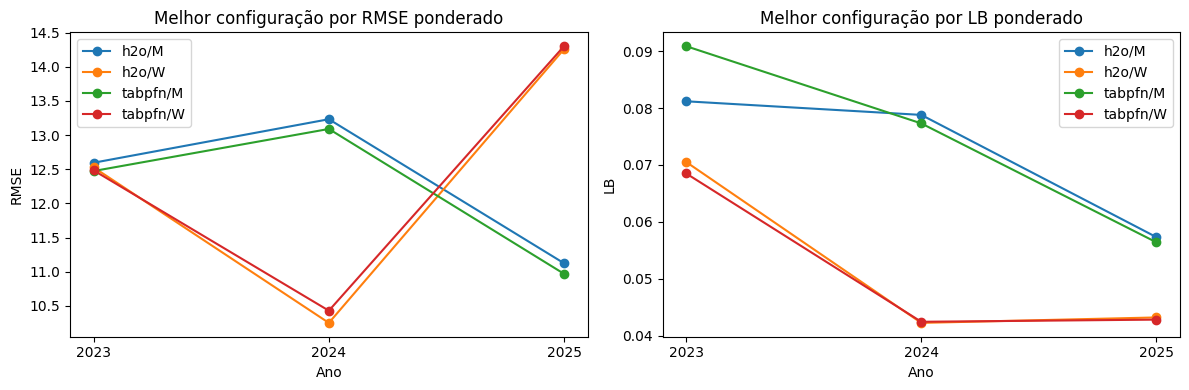

In [20]:
candidatos = candidatos_h2o + [c for banco in catalogos_tabpfn.values() for c in banco]
avaliacoes = avaliacao_h2o['avaliacoes'] + [r for a in avaliacoes_tabpfn.values() for r in a['avaliacoes']]
display(pd.DataFrame([{k: r.get(k) for k in ['Categoria', 'Abordagem', 'Candidato', 'Season', 'status', 'RMSE', 'LB', 'erro', 'recursos']} for r in avaliacoes]))
scores, ranking = rankings(avaliacoes, REFERENCIAS)
top3 = ranking.query('Posicao <= 3').copy()
display(scores, top3)
contagens = top3.groupby(['Abordagem', 'Metrica', 'Categoria']).size()
esperados = pd.MultiIndex.from_product([['h2o', 'tabpfn'], ['rmse', 'lb'], ['M', 'W']])
salvar_json(CHECKPOINTS / 'rankings.json', {'scores': scores.to_dict('records'), 'ranking': ranking.to_dict('records')})
assert contagens.reindex(esperados, fill_value=0).eq(3).all(), 'Faltam três candidatos válidos em algum ranking: consulte falhas/orçamento e retome.'
tempos = pd.DataFrame([{'Abordagem': r['Abordagem'], 'Categoria': r['Categoria'],
    'Candidato': r['Candidato'], 'Segundos': r['recursos'].get('segundos', 0)} for r in avaliacoes])
display(tempos.groupby(['Abordagem', 'Categoria', 'Candidato']).Segundos.sum().reset_index())
display(tempos.groupby(['Abordagem', 'Categoria']).Segundos.sum().rename('SegundosValidacao').reset_index())
display(pd.DataFrame([{'Categoria': cat, 'SegundosDescobertaH2O': d['segundos']} for cat, d in descobertas.items()]))
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metrica in zip(axes, ['RMSE', 'LB']):
    melhores = ranking.loc[(ranking.Posicao == 1) & ranking.Metrica.eq(metrica.lower())]
    for _, row in melhores.iterrows():
        ax.plot(ANOS_VALIDACAO, [row[f'{metrica}_{ano}'] for ano in ANOS_VALIDACAO], marker='o', label=f"{row.Abordagem}/{row.Categoria}")
    ax.set(title=f'Melhor configuração por {metrica} ponderado', xlabel='Ano', ylabel=metrica, xticks=ANOS_VALIDACAO)
    ax.legend()
plt.tight_layout()
plt.show()

## Confrontos de 2026

In [21]:
sample_submission = dados["M"]["sample_submission"]
confrontos = preparar_confrontos(
    sample_submission, seeds["M"], seeds["W"],
    dados["M"]["times"]["TeamID"], dados["W"]["times"]["TeamID"],
    temporada=TEMPORADA_PREVISAO,
)
stats_2026 = pd.concat([
    stats.loc[stats["Season"].eq(TEMPORADA_PREVISAO)]
    for stats in estatisticas.values()
], ignore_index=True)
confrontos = adicionar_estatisticas(confrontos, stats_2026, permitir_ausentes=True)
detalhes_2026 = pd.concat([
    stats.loc[stats["Season"].eq(TEMPORADA_PREVISAO)] for stats in detalhadas.values()
], ignore_index=True)
confrontos = adicionar_estatisticas_detalhadas(confrontos, detalhes_2026, permitir_ausentes=True)
participantes = confrontos["TemDuasSeeds"]
assert (confrontos["TeamA"] < confrontos["TeamB"]).all()
assert np.isfinite(confrontos.loc[participantes, FEATURES].to_numpy()).all()
stats_index = stats_2026.set_index(["Season", "TeamID"])
for nome in ["WinRate", "AvgPointsFor", "AvgPointsAgainst", "OppWinRate"]:
    pares = confrontos.loc[participantes]
    a = stats_index[nome].reindex(pd.MultiIndex.from_frame(pares[["Season", "TeamA"]])).to_numpy()
    b = stats_index[nome].reindex(pd.MultiIndex.from_frame(pares[["Season", "TeamB"]])).to_numpy()
    np.testing.assert_allclose(pares[f"{nome}Diff"], a - b)

lookup = detalhes_2026.set_index(["Season", "TeamID"])
pares = confrontos.loc[participantes]
for nome in ESTATISTICAS_DETALHADAS:
    a = lookup[nome].reindex(pd.MultiIndex.from_frame(pares[["Season", "TeamA"]])).to_numpy()
    b = lookup[nome].reindex(pd.MultiIndex.from_frame(pares[["Season", "TeamB"]])).to_numpy()
    np.testing.assert_allclose(pares[nome + "Diff"], a - b)

## Treino final e até 12 submissions

Todo o histórico disponível até 2025. Configurações que vencem nos dois rankings
são reajustadas apenas uma vez por categoria; suas previsões ficam em checkpoint.
Sem sigmoid ou clipping. Pares sem duas seeds recebem o fallback 0 do projeto.
Falhas não são substituídas pelo próximo colocado; CSVs idênticos são identificados.

In [22]:
resultado_final = gerar_submissions(jogos, candidatos, ranking, confrontos, sample_submission,
    features=FEATURES, pasta=CHECKPOINTS / 'final', destino=raiz / 'submissions')
display(pd.DataFrame(resultado_final['submissions']))
display(pd.DataFrame(resultado_final['falhas']))
display(pd.DataFrame(resultado_final['tempos_finais']))

,Arquivo,Abordagem,Metrica,Posicao,ModeloM,ModeloW,Linhas,IdenticaA
0,submission_exp11_h2o_lb_top1_2026.csv,h2o,lb,1,M_h2o_a5fb385a7ba264e4,W_h2o_f915b2ce8c23549e,132133,None
1,submission_exp11_h2o_lb_top2_2026.csv,h2o,lb,2,M_h2o_be36c1baf937f89e,W_h2o_99cabd64d82f06f5,132133,None
2,submission_exp11_h2o_lb_top3_2026.csv,h2o,lb,3,M_h2o_2e2d29e3542f6eb6,W_h2o_7b6d1bbdda8a2b5f,132133,None
3,submission_exp11_h2o_rmse_top1_2026.csv,h2o,rmse,1,M_h2o_afec215223f32962,W_h2o_f915b2ce8c23549e,132133,None
4,submission_exp11_h2o_rmse_top2_2026.csv,h2o,rmse,2,M_h2o_01fbfc68a223445a,W_h2o_8ba83e6ac7a73b39,132133,None
5,submission_exp11_h2o_rmse_top3_2026.csv,h2o,rmse,3,M_h2o_a5fb385a7ba264e4,W_h2o_189f2ec6c442be6f,132133,None
6,submission_exp11_tabpfn_lb_top1_2026.csv,tabpfn,lb,1,M_tabpfn_V3_5_4,W_tabpfn_V3_5_32,132133,None
7,submission_exp11_tabpfn_lb_top2_2026.csv,tabpfn,lb,2,M_tabpfn_V3_5_8,W_tabpfn_V3_5_16,132133,None
8,submission_exp11_tabpfn_lb_top3_2026.csv,tabpfn,lb,3,M_tabpfn_V3_5_32,W_tabpfn_V3_5_8,132133,None
9,submission_exp11_tabpfn_rmse_top1_2026.csv,tabpfn,rmse,1,M_tabpfn_V3_5_FAST_4,W_tabpfn_V3_5_32,132133,None


""


,Candidato,Segundos
0,M_h2o_afec215223f32962,1.720897
1,M_h2o_01fbfc68a223445a,1.482489
2,M_h2o_a5fb385a7ba264e4,1.143963
3,W_h2o_f915b2ce8c23549e,0.909173
4,W_h2o_8ba83e6ac7a73b39,1.120301
5,W_h2o_189f2ec6c442be6f,1.128304
6,M_tabpfn_V3_5_FAST_4,1.611012
7,M_tabpfn_V3_5_FAST_8,2.095942
8,M_tabpfn_V3_5_FAST_16,3.669128
9,W_tabpfn_V3_5_32,10.992647


## Registro e Kaggle

Referência informada do Exp. 8: **0.04783**. Não usamos Kaggle na seleção.
As médias 2021–2025 do Exp. 8 não são comparáveis diretamente a estes scores
ponderados de 2023–2025. Registre aqui os scores do Exp. 11 após submeter.

Checkpoints em `checkpoints/exp11` são locais, ignorados pelo Git e identificados
por dados, parâmetros e versões. Busca interrompida antes de terminar precisa ser
refeita; buscas completas e cortes completos são retomados. Falhas ficam registradas;
use `REPETIR_FALHAS=True` após corrigir a causa. Mudanças de versões invalidam o cache.

In [23]:
registro = {'features': FEATURES, 'anos': ANOS_VALIDACAO, 'seed': SEED, 'versoes': versoes(),
    'max_models_h2o': MAX_MODELS_H2O, 'top_base_h2o': TOP_BASE_H2O, 'folds_descoberta': N_FOLDS,
    'referencias': REFERENCIAS.to_dict('records'), 'orcamentos_tabpfn': orcamentos,
    'ambiente_tabpfn': ambiente_tabpfn, 'ambiente_h2o': ambiente_h2o,
    'candidatos': candidatos, 'top3': top3.to_dict('records'), 'submissions': resultado_final}
salvar_json(CHECKPOINTS / 'registro.json', registro)
display({k: registro[k] for k in ['features', 'anos', 'seed', 'versoes']})

{'features': ['SeedDif',
  'WinRateDiff',
  'AvgPointsForDiff',
  'AvgPointsAgainstDiff',
  'OppWinRateDiff',
  'FGPercentageDiff',
  'ThreePointPercentageDiff',
  'FTPercentageDiff',
  'AssistsPerGameDiff',
  'OffensiveReboundsPerGameDiff',
  'DefensiveReboundsPerGameDiff',
  'TurnoversPerGameDiff',
  'StealsPerGameDiff',
  'BlocksPerGameDiff'],
 'anos': [2023, 2024, 2025],
 'seed': 42,
 'versoes': {'h2o': '3.46.0.12',
  'tabpfn': '9.2.0',
  'torch': '2.11.0+cu128',
  'numpy': '2.2.6',
  'pandas': '2.3.2',
  'scikit-learn': '1.7.1',
  'psutil': '7.2.2'}}